# Ski Trip Planner — Weather Data Exploration

## Objective
Explore historical weather data collected from Alpine ski destinations to understand data quality, seasonal patterns, and the variables that could be useful for predicting ski conditions.

## Dataset
- 18 ski destinations across Switzerland, France, and Italy
- 21 weather points
- 5 winter seasons (2021–2022 to 2025–2026)
- Hourly weather data from Open-Meteo

## Questions
1. Is the dataset complete and consistent across destinations and seasons?
2. How do temperature, snowfall, and snow depth vary throughout the winter?
3. Are there meaningful differences between ski destinations?
4. Which weather variables could be useful for predicting ski conditions?

## 1. Loading and inspecting the raw data


In [1]:
from pathlib import Path
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "open-meteo"

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Data directory exists:", DATA_DIR.exists())

Project root: /Users/martaczurylo/Documents/ski-trip-planner
Data directory: /Users/martaczurylo/Documents/ski-trip-planner/data/raw/open-meteo
Data directory exists: True


In [3]:
json_files = sorted(DATA_DIR.rglob("*.json"))

print(f"Total JSON files: {len(json_files)}")

Total JSON files: 105


In [4]:
for file in json_files[:10]:
    print(file.relative_to(DATA_DIR))

1-crans-montana_crans-montana/2021-2022.json
1-crans-montana_crans-montana/2022-2023.json
1-crans-montana_crans-montana/2023-2024.json
1-crans-montana_crans-montana/2024-2025.json
1-crans-montana_crans-montana/2025-2026.json
10-le-grand-bornand_le-grand-bornand/2021-2022.json
10-le-grand-bornand_le-grand-bornand/2022-2023.json
10-le-grand-bornand_le-grand-bornand/2023-2024.json
10-le-grand-bornand_le-grand-bornand/2024-2025.json
10-le-grand-bornand_le-grand-bornand/2025-2026.json


In [5]:
sample_file = json_files[0]

with open(sample_file, "r") as f:
    sample_data = json.load(f)

print("File:", sample_file.name)
print("Top-level keys:")
print(sample_data.keys())

File: 2021-2022.json
Top-level keys:
dict_keys(['season', 'season_start_year', 'destination', 'destination_id', 'ski_area', 'weather_point_id', 'weather_point', 'request', 'fetched_at_utc', 'response'])


In [6]:
response = sample_data["response"]

print("Response keys:")
print(response.keys())

print("\nHourly variables:")
print(response["hourly"].keys())

print("\nUnits:")
print(response["hourly_units"])


Response keys:
dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])

Hourly variables:
dict_keys(['time', 'temperature_2m', 'precipitation', 'snowfall', 'snow_depth', 'wind_speed_10m'])

Units:
{'time': 'iso8601', 'temperature_2m': '°C', 'precipitation': 'mm', 'snowfall': 'cm', 'snow_depth': 'm', 'wind_speed_10m': 'km/h'}


In [7]:
hourly = response["hourly"]

for variable, values in hourly.items():
    print(f"{variable}: {len(values)} observations")

time: 4344 observations
temperature_2m: 4344 observations
precipitation: 4344 observations
snowfall: 4344 observations
snow_depth: 4344 observations
wind_speed_10m: 4344 observations


In [8]:
times = hourly["time"]

print("First timestamp:", times[0])
print("Last timestamp:", times[-1])
print("Number of timestamps:", len(times))

First timestamp: 2021-11-01T00:00
Last timestamp: 2022-04-30T23:00
Number of timestamps: 4344


In [9]:
timestamps = pd.to_datetime(times)

print("Data type:", timestamps.dtype)
print("First timestamp:", timestamps[0])
print("Last timestamp:", timestamps[-1])

Data type: datetime64[us]
First timestamp: 2021-11-01 00:00:00
Last timestamp: 2022-04-30 23:00:00


The original Open-Meteo request metadata was checked: requests use `timezone=UTC`. The hourly timestamps are therefore parsed as UTC-aware values (`utc=True`) and stored in UTC.


## 2. Data completeness and timestamp validation


In [10]:
# Check for missing data

weather_variables = [
    "temperature_2m",
    "precipitation",
    "snowfall",
    "snow_depth",
    "wind_speed_10m",
]

for variable in weather_variables:
    values = pd.Series(hourly[variable])
    missing = values.isna().sum()
    print(f"{variable}: {missing} missing values")

temperature_2m: 0 missing values
precipitation: 0 missing values
snowfall: 0 missing values
snow_depth: 0 missing values
wind_speed_10m: 0 missing values


In [11]:
# Make sure that the data points are really separated by 1h

time_differences = timestamps.to_series().diff().dropna()

print("Unique time intervals:")
print(time_differences.value_counts())

Unique time intervals:
0 days 01:00:00    4343
Name: count, dtype: int64


In [12]:
# Make detailed checks on all files, print out the first 5 
file_checks = []

for file in json_files:
    with open(file, "r") as f:
        data = json.load(f)

    hourly_data = data["response"]["hourly"]

    file_checks.append({
        "file": file.name,
        "destination": data["destination"],
        "season": data["season"],
        "n_timestamps": len(hourly_data["time"]),
        "missing_temperature": pd.isna(hourly_data["temperature_2m"]).sum(),
        "missing_precipitation": pd.isna(hourly_data["precipitation"]).sum(),
        "missing_snowfall": pd.isna(hourly_data["snowfall"]).sum(),
        "missing_snow_depth": pd.isna(hourly_data["snow_depth"]).sum(),
        "missing_wind": pd.isna(hourly_data["wind_speed_10m"]).sum(),
    })

quality_df = pd.DataFrame(file_checks)

quality_df.head()

,file,destination,season,n_timestamps,missing_temperature,missing_precipitation,missing_snowfall,missing_snow_depth,missing_wind
0,2021-2022.json,Crans Montana,2021-2022,4344,0,0,0,0,0
1,2022-2023.json,Crans Montana,2022-2023,4344,0,0,0,0,0
2,2023-2024.json,Crans Montana,2023-2024,4368,0,0,0,0,0
3,2024-2025.json,Crans Montana,2024-2025,4344,0,0,0,0,0
4,2025-2026.json,Crans Montana,2025-2026,4344,0,0,0,0,0


In [13]:
# Make basic checks on all files
print("Total files checked:", len(quality_df))
print("Unique destinations:", quality_df["destination"].nunique())
print("Unique seasons:", quality_df["season"].nunique())

Total files checked: 105
Unique destinations: 18
Unique seasons: 5


In [14]:
# Check observation counts
print("Observation counts:")
print(quality_df["n_timestamps"].value_counts())

# Check missing weather values
missing_columns = [
    "missing_temperature",
    "missing_precipitation",
    "missing_snowfall",
    "missing_snow_depth",
    "missing_wind",
]

print("\nTotal missing values across the dataset:")
print(quality_df[missing_columns].sum())

Observation counts:
n_timestamps
4344    84
4368    21
Name: count, dtype: int64

Total missing values across the dataset:
missing_temperature      0
missing_precipitation    0
missing_snowfall         0
missing_snow_depth       0
missing_wind             0
dtype: int64


In [15]:
# Confirm that the extra number of timestamps comes from 2024 being a leap year
quality_df.groupby("season")["n_timestamps"].value_counts().sort_index()

season     n_timestamps
2021-2022  4344            21
2022-2023  4344            21
2023-2024  4368            21
2024-2025  4344            21
2025-2026  4344            21
Name: count, dtype: int64

In [16]:
continuity_checks = []

for file in json_files:
    with open(file, "r") as f:
        data = json.load(f)

    times = pd.to_datetime(data["response"]["hourly"]["time"])
    differences = times.to_series().diff().dropna()

    continuity_checks.append({
        "file": file.name,
        "destination": data["destination"],
        "season": data["season"],
        "n_timestamps": len(times),
        "n_unique_timestamps": times.nunique(),
        "n_gaps_or_irregular_intervals": (differences != pd.Timedelta(hours=1)).sum(),
    })
    
continuity_df = pd.DataFrame(continuity_checks)

continuity_df.head()

,file,destination,season,n_timestamps,n_unique_timestamps,n_gaps_or_irregular_intervals
0,2021-2022.json,Crans Montana,2021-2022,4344,4344,0
1,2022-2023.json,Crans Montana,2022-2023,4344,4344,0
2,2023-2024.json,Crans Montana,2023-2024,4368,4368,0
3,2024-2025.json,Crans Montana,2024-2025,4344,4344,0
4,2025-2026.json,Crans Montana,2025-2026,4344,4344,0


## 3. Range checks and distributions


In [17]:
# Inspect plausible ranges for each weather variable across all source files.
# These checks help identify suspicious values but do not automatically reject data.

weather_variables = [
    "temperature_2m",
    "precipitation",
    "snowfall",
    "snow_depth",
    "wind_speed_10m",
]

value_checks = []

for file in json_files:
    with open(file, "r") as f:
        data = json.load(f)

    hourly_data = data["response"]["hourly"]

    for variable in weather_variables:
        values = pd.Series(hourly_data[variable])

        value_checks.append({
            "destination": data["destination"],
            "season": data["season"],
            "variable": variable,
            "minimum": values.min(),
            "maximum": values.max(),
        })

values_df = pd.DataFrame(value_checks)

values_df.groupby("variable")[ ["minimum", "maximum"] ].agg(["min", "max"])


minimum        maximum       
                   min    max     min    max
variable                                    
precipitation      0.0   0.00    3.70  10.70
snow_depth         0.0  33.33    0.58  33.33
snowfall           0.0   0.00    2.59   7.49
temperature_2m   -28.5 -12.70    1.80  20.60
wind_speed_10m     0.0   0.40   10.30  31.30

In [18]:
# Investigate snow-depth values above 10 m, which may indicate a data anomaly.
values_df[
    (values_df["variable"] == "snow_depth") &
    (values_df["maximum"] > 10)
]


,destination,season,variable,minimum,maximum
393,Zermatt,2024-2025,snow_depth,2.91,33.33
398,Zermatt,2025-2026,snow_depth,33.33,33.33


In [19]:
distribution_data = {variable: [] for variable in weather_variables}

for file in json_files:
    with open(file, "r") as f:
        data = json.load(f)

    hourly_data = data["response"]["hourly"]

    for variable in weather_variables:
        distribution_data[variable].extend(hourly_data[variable])

distribution_summary = pd.DataFrame({
    variable: pd.Series(values).describe(percentiles=[0.25, 0.50, 0.75])
    for variable, values in distribution_data.items()
})

distribution_summary

,temperature_2m,precipitation,snowfall,snow_depth,wind_speed_10m
count,456624.000000,456624.000000,456624.000000,456624.000000,456624.000000
mean,-2.820691,0.188638,0.104857,1.693847,4.497265
std,5.531087,0.553911,0.345876,3.391106,2.740255
min,-28.500000,0.000000,0.000000,0.000000,0.000000
25%,-6.400000,0.000000,0.000000,0.660000,2.500000
50%,-2.600000,0.000000,0.000000,1.140000,4.100000
75%,0.800000,0.100000,0.000000,1.670000,6.000000
max,20.600000,10.700000,7.490000,33.330000,31.300000


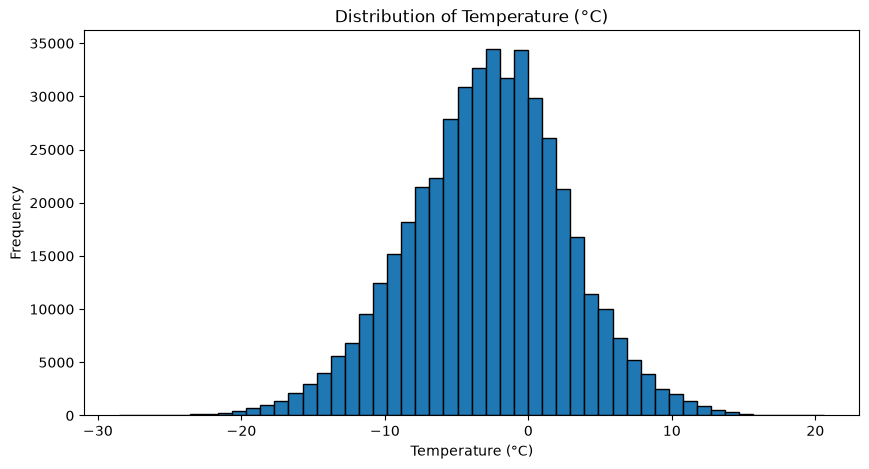

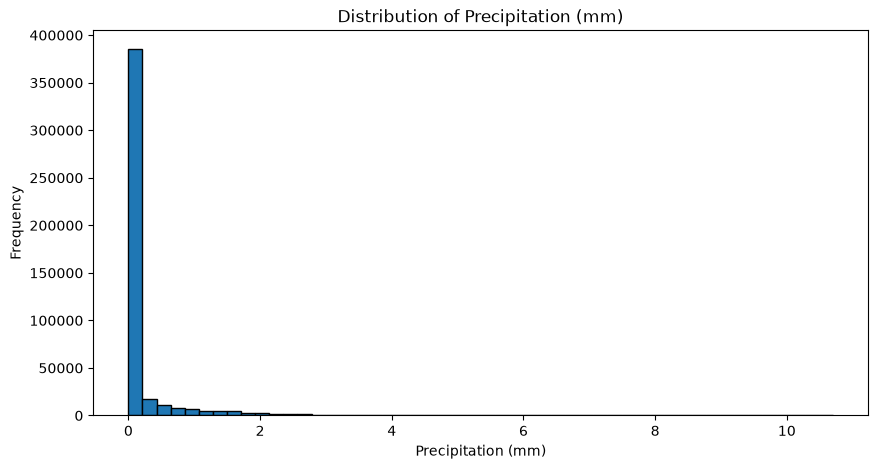

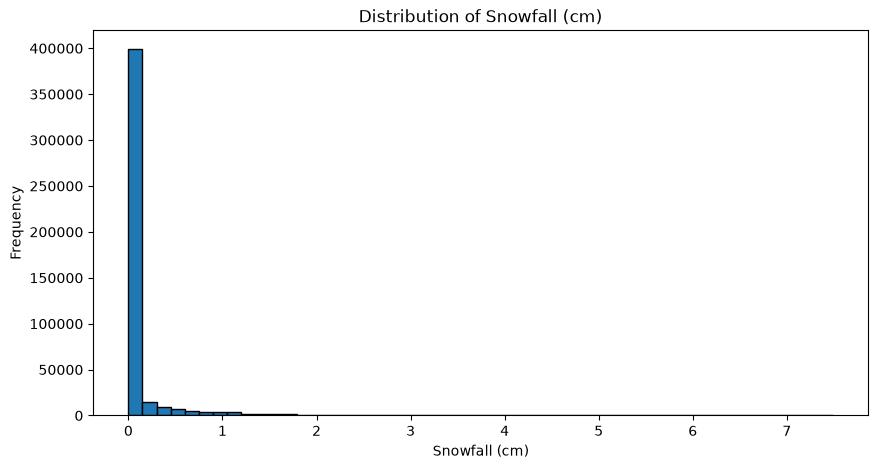

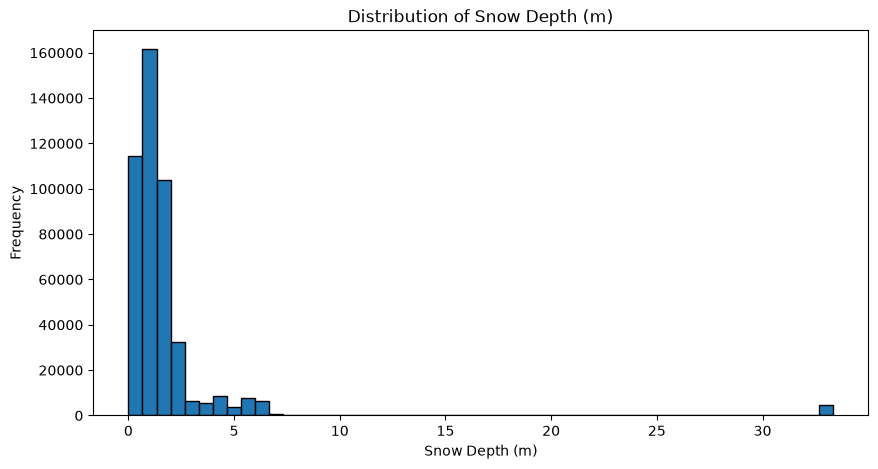

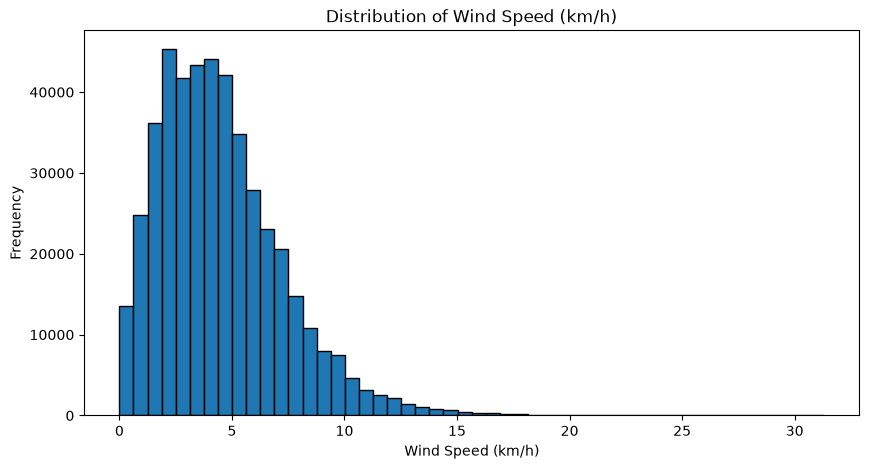

In [20]:
# Visualize the pooled hourly distributions of the weather variables.
# Pooling all destinations, weather points and seasons hides local differences.

variables_to_plot = {
    "temperature_2m": "Temperature (°C)",
    "precipitation": "Precipitation (mm)",
    "snowfall": "Snowfall (cm)",
    "snow_depth": "Snow Depth (m)",
    "wind_speed_10m": "Wind Speed (km/h)",
}

for variable, label in variables_to_plot.items():
    plt.figure(figsize=(10, 5))

    plt.hist(
        distribution_data[variable],
        bins=50,
        edgecolor="black"
    )

    plt.title(f"Distribution of {label}")
    plt.xlabel(label)
    plt.ylabel("Frequency")

    plt.show()


## 4. Build hourly and daily exploratory datasets


In [21]:
hourly_records = []

for file in json_files:
    with open(file, "r") as f:
        data = json.load(f)

    hourly_data = data["response"]["hourly"]

    df = pd.DataFrame({
        "timestamp": pd.to_datetime(hourly_data["time"]),
        "temperature": hourly_data["temperature_2m"],
        "precipitation": hourly_data["precipitation"],
        "snowfall": hourly_data["snowfall"],
        "snow_depth": hourly_data["snow_depth"],
        "wind_speed": hourly_data["wind_speed_10m"],
    })

    df["destination"] = data["destination"]
    df["destination_id"] = data["destination_id"]
    df["season"] = data["season"]
    df["weather_point_id"] = data["weather_point_id"]
    df["weather_point"] = data["weather_point"]

    hourly_records.append(df)

hourly_df = pd.concat(hourly_records, ignore_index=True)

hourly_df.head()

,timestamp,temperature,precipitation,snowfall,snow_depth,wind_speed,destination,destination_id,season,weather_point_id,weather_point
0,2021-11-01 00:00:00,-1.4,0.0,0.0,0.0,5.4,Crans Montana,1,2021-2022,1-crans-montana,NaN
1,2021-11-01 01:00:00,-1.3,0.0,0.0,0.0,6.2,Crans Montana,1,2021-2022,1-crans-montana,NaN
2,2021-11-01 02:00:00,-1.2,0.0,0.0,0.0,5.1,Crans Montana,1,2021-2022,1-crans-montana,NaN
3,2021-11-01 03:00:00,-1.1,0.0,0.0,0.0,4.7,Crans Montana,1,2021-2022,1-crans-montana,NaN
4,2021-11-01 04:00:00,-1.1,0.0,0.0,0.0,3.7,Crans Montana,1,2021-2022,1-crans-montana,NaN


In [22]:
hourly_df["date"] = hourly_df["timestamp"].dt.date

daily_df = (
    hourly_df
    .groupby([
        "destination",
        "destination_id",
        "season",
        "weather_point_id",
        "date"
    ])
    .agg(
        precipitation_daily=("precipitation", "sum"),
        snowfall_daily=("snowfall", "sum"),
        temperature_mean=("temperature", "mean"),
        temperature_min=("temperature", "min"),
        temperature_max=("temperature", "max"),
        snow_depth_mean=("snow_depth", "mean"),
        snow_depth_max=("snow_depth", "max"),
        snow_depth_end=("snow_depth", "last"),
        wind_mean=("wind_speed", "mean"),
        wind_max=("wind_speed", "max"),
    )
    .reset_index()
)

daily_df.head(10)

,destination,destination_id,season,weather_point_id,date,precipitation_daily,snowfall_daily,temperature_mean,temperature_min,temperature_max,snow_depth_mean,snow_depth_max,snow_depth_end,wind_mean,wind_max
0,4 Vallées,2,2021-2022,2-4-vallees,2021-11-01,13.3,2.87,-0.166667,-4.4,3.2,0.053750,0.09,0.09,3.400000,5.2
1,4 Vallées,2,2021-2022,2-4-vallees,2021-11-02,0.9,0.63,-4.633333,-8.6,-1.1,0.090000,0.09,0.09,4.412500,6.8
2,4 Vallées,2,2021-2022,2-4-vallees,2021-11-03,20.3,14.14,-3.312500,-6.0,-1.5,0.132500,0.20,0.20,4.233333,9.1
3,4 Vallées,2,2021-2022,2-4-vallees,2021-11-04,5.0,3.50,-7.075000,-13.1,-4.3,0.217917,0.22,0.22,4.662500,6.1
4,4 Vallées,2,2021-2022,2-4-vallees,2021-11-05,0.0,0.00,-7.950000,-12.6,-3.5,0.220000,0.22,0.22,4.058333,7.0
5,4 Vallées,2,2021-2022,2-4-vallees,2021-11-06,0.0,0.00,-5.320833,-11.5,-0.7,0.220000,0.22,0.22,3.312500,6.0
6,4 Vallées,2,2021-2022,2-4-vallees,2021-11-07,0.0,0.00,-1.437500,-9.9,2.1,0.219167,0.22,0.21,4.033333,7.6
7,4 Vallées,2,2021-2022,2-4-vallees,2021-11-08,0.0,0.00,-4.229167,-9.4,0.0,0.211667,0.22,0.21,3.750000,7.9
8,4 Vallées,2,2021-2022,2-4-vallees,2021-11-09,0.0,0.00,-2.562500,-10.2,5.2,0.210000,0.21,0.21,5.154167,8.4
9,4 Vallées,2,2021-2022,2-4-vallees,2021-11-10,0.1,0.00,1.008333,-2.9,4.7,0.205417,0.21,0.20,5.908333,8.7


In [23]:
print("Hourly dataset shape:", hourly_df.shape)
print("Daily dataset shape:", daily_df.shape)

print("\nDestinations:", daily_df["destination"].nunique())
print("Seasons:", daily_df["season"].nunique())

print("\nDate range:")
print(daily_df["date"].min(), "to", daily_df["date"].max())

Hourly dataset shape: (456624, 12)
Daily dataset shape: (19026, 15)

Destinations: 18
Seasons: 5

Date range:
2021-11-01 to 2026-04-30


## 5. Daily precipitation and snowfall


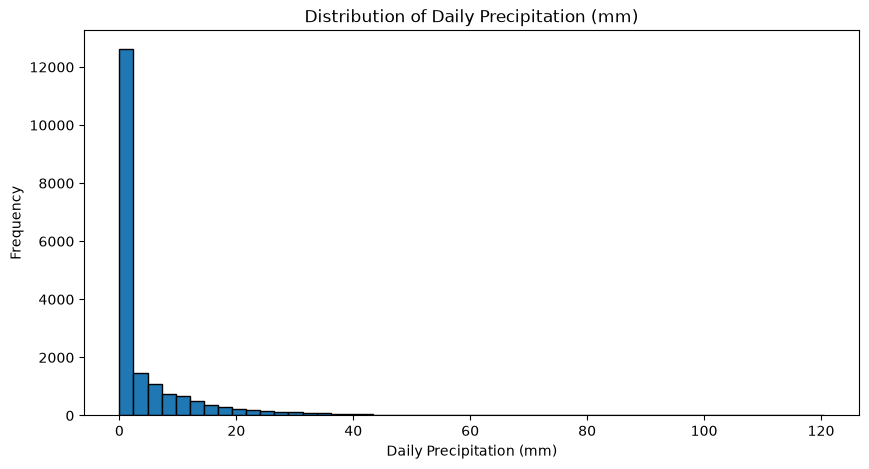

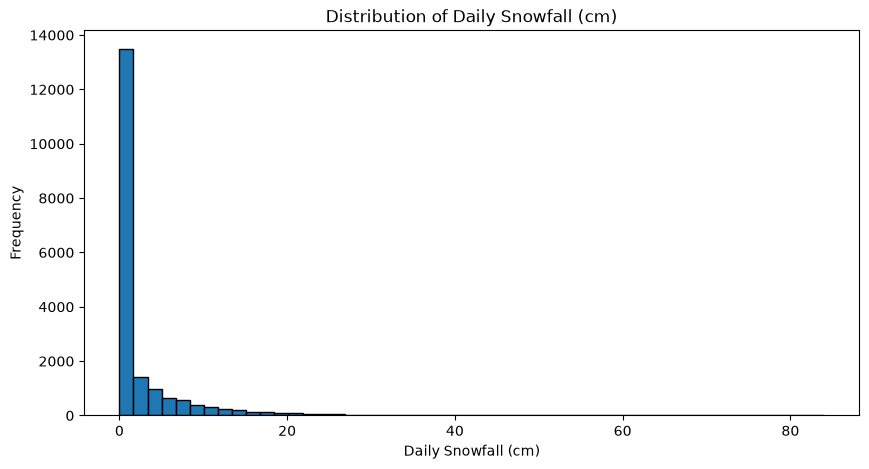

In [24]:
daily_variables = {
    "precipitation_daily": "Daily Precipitation (mm)",
    "snowfall_daily": "Daily Snowfall (cm)",
}

for variable, label in daily_variables.items():
    plt.figure(figsize=(10, 5))

    plt.hist(daily_df[variable], bins=50, edgecolor="black")

    plt.title(f"Distribution of {label}")
    plt.xlabel(label)
    plt.ylabel("Frequency")

    plt.show()

### Daily precipitation and snowfall

Daily precipitation and snowfall distributions are strongly right-skewed, with a large proportion of zero-value days and occasional high-intensity events. This reflects the episodic nature of winter precipitation. Consequently, mean values alone may not fully capture typical conditions, and median values, cumulative snowfall and recent snowfall windows may be more informative for ski-condition analysis.


In [25]:
daily_df[list(daily_variables.keys())].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
)

,precipitation_daily,snowfall_daily
count,19026.000000,19026.000000
mean,4.527315,2.516571
std,8.826491,5.402920
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.200000,0.000000
75%,5.200000,2.450000
90%,14.600000,8.400000
95%,22.900000,13.650000
max,120.500000,84.000000


In [26]:
for variable in daily_variables:
    zero_days = (daily_df[variable] == 0).mean() * 100

    print(f"{variable}: {zero_days:.1f}% of days have zero values")

precipitation_daily: 45.1% of days have zero values
snowfall_daily: 52.6% of days have zero values


## 6. Seasonal patterns


In [27]:
monthly_df = daily_df.copy()

monthly_df["month"] = pd.to_datetime(monthly_df["date"]).dt.month

monthly_temperature = (
    monthly_df
    .groupby("month")
    .agg(
        temperature_mean=("temperature_mean", "mean"),
        temperature_min=("temperature_min", "mean"),
        temperature_max=("temperature_max", "mean"),
    )
)

monthly_temperature

,temperature_mean,temperature_min,temperature_max
month,,,
1,-5.514461,-9.464670,-1.419232
2,-3.511754,-7.692097,0.820263
3,-2.446027,-6.920000,1.833886
4,0.507132,-3.886984,4.679238
11,-1.993676,-6.035429,2.112476
12,-3.893753,-7.615269,0.004823


In [28]:
plot_data = monthly_temperature.reindex([11, 12, 1, 2, 3, 4]).copy()

plot_data["month_label"] = ["Nov", "Dec", "Jan", "Feb", "Mar", "Apr"]

plot_data

,temperature_mean,temperature_min,temperature_max,month_label
month,,,,
11,-1.993676,-6.035429,2.112476,Nov
12,-3.893753,-7.615269,0.004823,Dec
1,-5.514461,-9.464670,-1.419232,Jan
2,-3.511754,-7.692097,0.820263,Feb
3,-2.446027,-6.920000,1.833886,Mar
4,0.507132,-3.886984,4.679238,Apr


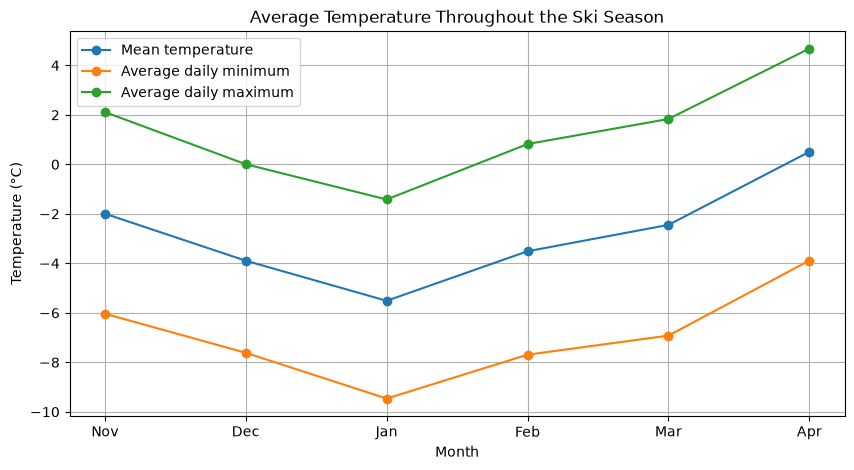

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(
    plot_data["month_label"],
    plot_data["temperature_mean"],
    marker="o",
    label="Mean temperature"
)

plt.plot(
    plot_data["month_label"],
    plot_data["temperature_min"],
    marker="o",
    label="Average daily minimum"
)

plt.plot(
    plot_data["month_label"],
    plot_data["temperature_max"],
    marker="o",
    label="Average daily maximum"
)

plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.title("Average Temperature Throughout the Ski Season")

plt.legend()
plt.grid(True)

plt.show()

In [30]:
daily_df["month"] = pd.to_datetime(daily_df["date"]).dt.month
monthly_snow = (
    daily_df
    .groupby("month")
    .agg(
        snow_depth_mean=("snow_depth_mean", "mean"),
        snow_depth_max=("snow_depth_max", "mean"),
    )
)
monthly_snow

,snow_depth_mean,snow_depth_max
month,,
1,1.822274,1.844261
2,1.956724,1.974424
3,2.055944,2.074384
4,1.986143,2.007133
11,0.897441,0.913121
12,1.452038,1.471914


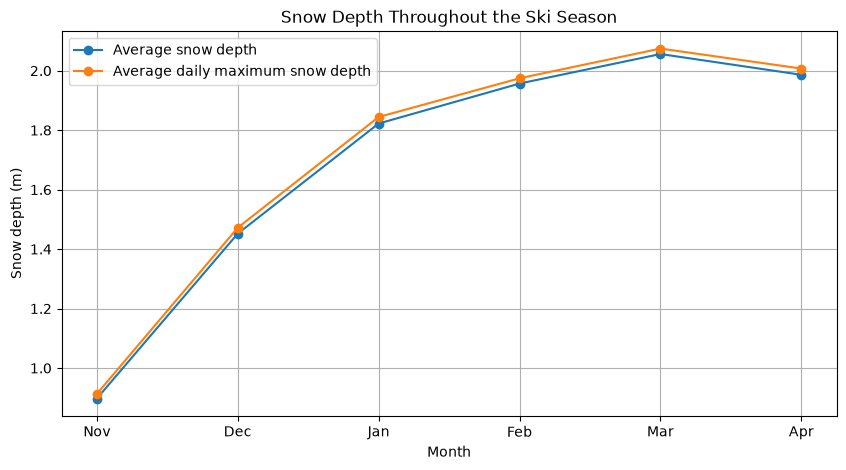

In [31]:
plot_snow = monthly_snow.reindex([11, 12, 1, 2, 3, 4]).copy()

plot_snow["month_label"] = ["Nov", "Dec", "Jan", "Feb", "Mar", "Apr"]

plt.figure(figsize=(10, 5))

plt.plot(
    plot_snow["month_label"],
    plot_snow["snow_depth_mean"],
    marker="o",
    label="Average snow depth"
)

plt.plot(
    plot_snow["month_label"],
    plot_snow["snow_depth_max"],
    marker="o",
    label="Average daily maximum snow depth"
)

plt.xlabel("Month")
plt.ylabel("Snow depth (m)")
plt.title("Snow Depth Throughout the Ski Season")

plt.legend()
plt.grid(True)

plt.show()


### Seasonal snow depth evolution

Average snow depth increases steadily from November through March, with the highest pooled values observed in March, followed by a slight decline in April. This reflects the typical seasonal accumulation of snow through winter and the beginning of spring melt.

The average snow depth and average daily maximum snow depth follow very similar patterns. However, these aggregated values include all destinations, weather points and seasons, as well as the previously identified Zermatt anomaly. Therefore, the seasonal trend is more informative than the absolute snow-depth values at this stage.

## 7. Destination comparisons


In [32]:
destination_summary = (
    daily_df
    .groupby("destination")
    .agg(
        average_snow_depth=("snow_depth_mean", "mean"),
        average_daily_snowfall=("snowfall_daily", "mean"),
        average_temperature=("temperature_mean", "mean"),
    )
    .sort_values("average_snow_depth", ascending=False)
)

destination_summary

,average_snow_depth,average_daily_snowfall,average_temperature
destination,,,
Zermatt,10.156861,2.282881,-9.536074
Chamonix,3.304777,3.067715,-2.529937
Courmayeur,1.550083,2.554382,-3.496978
Les Contamines,1.478116,3.394536,-2.149039
La Thuile,1.397613,3.249514,-5.133798
Saas-Fee,1.239479,2.428212,-5.890264
Crans Montana,1.210463,2.071490,-4.675635
Engelberg,1.169492,2.748852,-2.324867
Les 2 Alpes,1.167638,3.185927,-5.615324


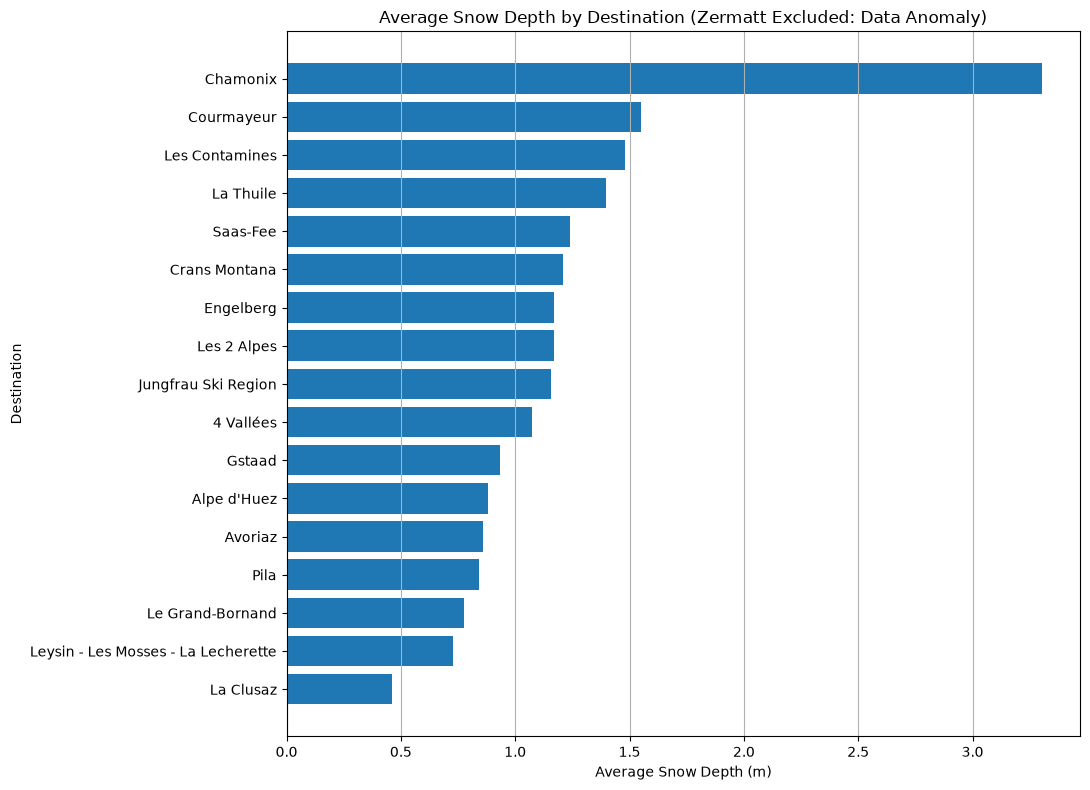

In [33]:
# Zermatt is excluded from this visualization because its snow-depth series
# contains previously identified anomalous values. The raw data remains unchanged.

snow_depth_plot = (
    destination_summary
    .drop("Zermatt")
    .sort_values("average_snow_depth", ascending=True)
)

plt.figure(figsize=(11, 8))

plt.barh(
    snow_depth_plot.index,
    snow_depth_plot["average_snow_depth"]
)

plt.xlabel("Average Snow Depth (m)")
plt.ylabel("Destination")
plt.title("Average Snow Depth by Destination (Zermatt Excluded: Data Anomaly)")
plt.grid(axis="x")
plt.tight_layout()
plt.show()


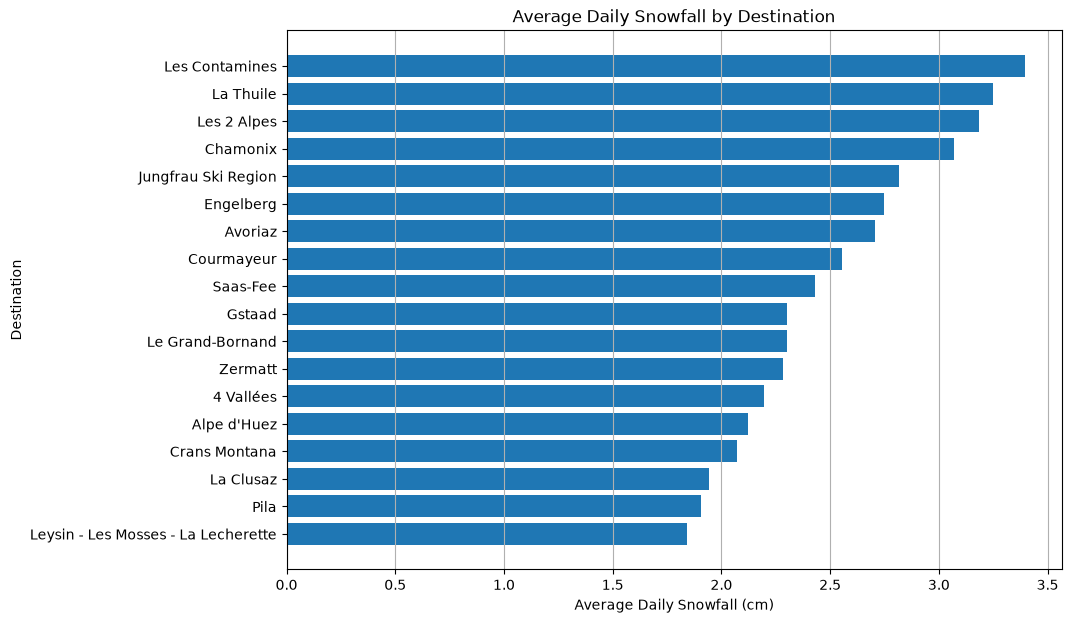

In [34]:
snowfall_plot = destination_summary.sort_values(
    "average_daily_snowfall",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    snowfall_plot.index,
    snowfall_plot["average_daily_snowfall"]
)

plt.xlabel("Average Daily Snowfall (cm)")
plt.ylabel("Destination")
plt.title("Average Daily Snowfall by Destination")
plt.grid(axis="x")

plt.show()

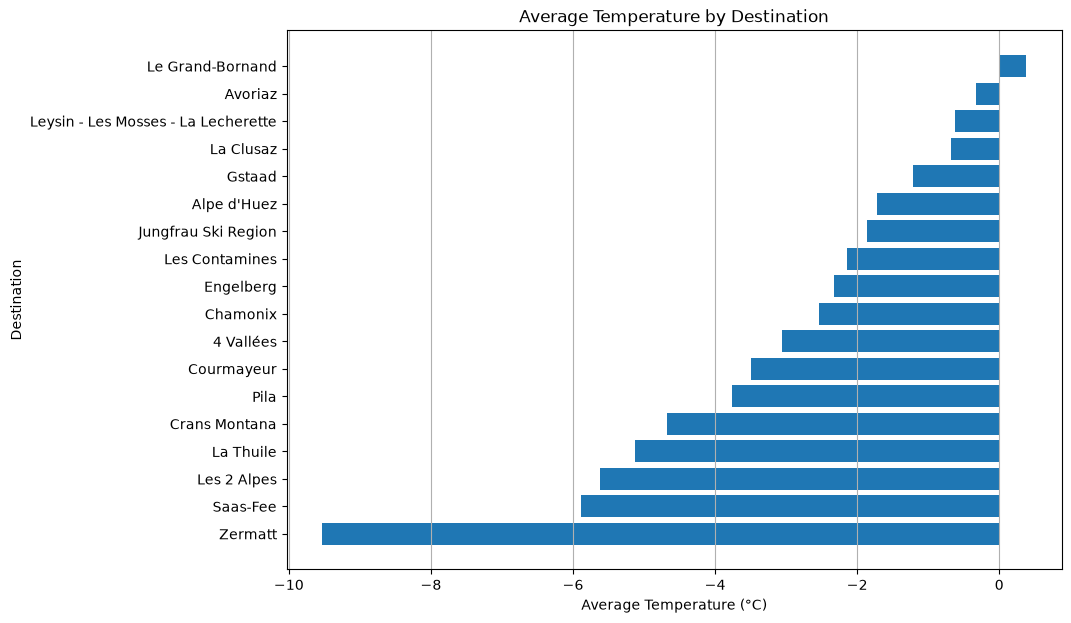

In [35]:
temperature_plot = destination_summary.sort_values(
    "average_temperature",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    temperature_plot.index,
    temperature_plot["average_temperature"]
)

plt.xlabel("Average Temperature (°C)")
plt.ylabel("Destination")
plt.title("Average Temperature by Destination")

plt.grid(axis="x")
plt.show()

## 8. Correlation analysis


In [36]:
correlation_variables = [
    "temperature_mean",
    "precipitation_daily",
    "snowfall_daily",
    "snow_depth_mean",
    "wind_mean",
]

correlation_matrix = daily_df[correlation_variables].corr()

correlation_matrix

,temperature_mean,precipitation_daily,snowfall_daily,snow_depth_mean,wind_mean
temperature_mean,1.000000,-0.000431,-0.106829,-0.222919,-0.100791
precipitation_daily,-0.000431,1.000000,0.905691,-0.008543,0.298042
snowfall_daily,-0.106829,0.905691,1.000000,0.010801,0.278134
snow_depth_mean,-0.222919,-0.008543,0.010801,1.000000,0.055793
wind_mean,-0.100791,0.298042,0.278134,0.055793,1.000000


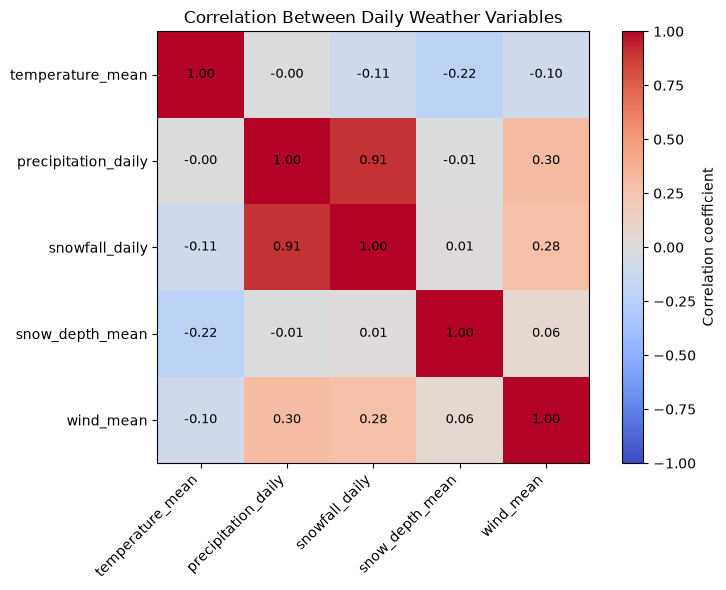

In [37]:
# Annotate the correlation matrix to make the values easier to interpret.
plt.figure(figsize=(8, 6))

plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.xticks(
    range(len(correlation_variables)),
    correlation_variables,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_variables)),
    correlation_variables
)

for row in range(correlation_matrix.shape[0]):
    for col in range(correlation_matrix.shape[1]):
        value = correlation_matrix.iloc[row, col]
        plt.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=9)

plt.colorbar(label="Correlation coefficient")
plt.title("Correlation Between Daily Weather Variables")
plt.tight_layout()
plt.show()


## 9. Structured dataset and snow-depth anomaly

The structured hourly dataset is built by `src/ski_planner/build_dataset.py` rather than in this notebook, so that the logic exists in one place and can be re-run and tested from the command line. The script:

- reads every cached JSON response and checks that the requests used `timezone=UTC`;
- builds one tidy table (one row per weather point and hour) with source-file provenance;
- validates the schema and writes `data/processed/weather_hourly.parquet`;
- reloads the Parquet file it wrote and compares it with the raw JSON (row counts, timestamps and exact values);
- flags snow-depth values above 10 m and exports them separately.

Run `python src/ski_planner/build_dataset.py` from the repository root before running this section.

In [38]:
# Verify timezone from the original request metadata (timezone=UTC).
with open(json_files[0], "r") as f:
    sample_data = json.load(f)

print("Request metadata:")
print(sample_data["request"])


Request metadata:
{'url': 'https://archive-api.open-meteo.com/v1/archive', 'params': {'latitude': 46.3334874, 'longitude': 7.4878235, 'start_date': '2021-11-01', 'end_date': '2022-04-30', 'hourly': 'temperature_2m,precipitation,snowfall,snow_depth,wind_speed_10m', 'timezone': 'UTC', 'cell_selection': 'land'}}


### 9.1 Load and inspect the processed dataset

In [39]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
parquet_path = PROCESSED_DIR / "weather_hourly.parquet"

structured_hourly_df = pd.read_parquet(parquet_path)

print("Shape:", structured_hourly_df.shape)
print("File size: {:.2f} MB".format(parquet_path.stat().st_size / (1024**2)))
print("Timestamp timezone:", structured_hourly_df["timestamp"].dt.tz)
print("Date range:", structured_hourly_df["timestamp"].min(), "to", structured_hourly_df["timestamp"].max())
print()
structured_hourly_df.info()

Shape: (456624, 14)
File size: 2.38 MB
Timestamp timezone: UTC
Date range: 2021-11-01 00:00:00+00:00 to 2026-04-30 23:00:00+00:00

<class 'pandas.DataFrame'>
RangeIndex: 456624 entries, 0 to 456623
Data columns (total 14 columns):
 #   Column              Non-Null Count   Dtype              
---  ------              --------------   -----              
 0   timestamp           456624 non-null  datetime64[us, UTC]
 1   temperature_2m      456624 non-null  float64            
 2   precipitation       456624 non-null  float64            
 3   snowfall            456624 non-null  float64            
 4   snow_depth          456624 non-null  float64            
 5   wind_speed_10m      456624 non-null  float64            
 6   destination         456624 non-null  str                
 7   destination_id      456624 non-null  str                
 8   ski_area            456624 non-null  str                
 9   season              456624 non-null  str                
 10  season_start_year   

### 9.2 Coverage and provenance

Each observation carries the relative path of the raw JSON response it came from, so any value can be traced back to its source.

In [40]:
print("Source files:", structured_hourly_df["source_file"].nunique())
print("Destinations:", structured_hourly_df["destination"].nunique())
print("Weather points:", structured_hourly_df["weather_point_id"].nunique())
print("Seasons:", structured_hourly_df["season"].nunique())
print("Missing weather values:", int(structured_hourly_df[
    ["temperature_2m", "precipitation", "snowfall", "snow_depth", "wind_speed_10m"]
].isna().sum().sum()))

structured_hourly_df.groupby("source_file").size().describe()

Source files: 105
Destinations: 18
Weather points: 21
Seasons: 5
Missing weather values: 0


count     105.000000
mean     4348.800000
std         9.646043
min      4344.000000
25%      4344.000000
50%      4344.000000
75%      4344.000000
max      4368.000000
dtype: float64

### 9.3 Snow-depth anomaly flagging

During exploratory analysis, unusually high snow-depth values of 33.33 m were identified at Zermatt. As the origin of these values could not be established, the observations were not corrected or removed.

The build script applies a general rule-based quality flag to **all destinations** when snow depth exceeds 10 m. This is a screening threshold rather than a scientifically validated physical limit. Flagged observations are retained in the main dataset (column `snow_depth_anomaly`) and exported separately for further inspection. Additional checks for abrupt jumps and flat-lined stretches are planned as further data-quality diagnostics.

In [41]:
anomaly_path = PROCESSED_DIR / "flagged_snow_depth_anomalies.parquet"
flagged_snow_depth = pd.read_parquet(anomaly_path)

# The separate export must match the flag in the main dataset
assert len(flagged_snow_depth) == int(structured_hourly_df["snow_depth_anomaly"].sum())

print(f"Flagged observations: {len(flagged_snow_depth):,} "
      f"({len(flagged_snow_depth) / len(structured_hourly_df):.2%} of the dataset)")
print("Flagged destinations:", sorted(flagged_snow_depth["destination"].unique()))
print("Flagged seasons:", sorted(flagged_snow_depth["season"].unique()))
print("Date range:", flagged_snow_depth["timestamp"].min(), "to", flagged_snow_depth["timestamp"].max())
print()
print(flagged_snow_depth["snow_depth"].value_counts().sort_index())

Flagged observations: 4,513 (0.99% of the dataset)
Flagged destinations: ['Zermatt']
Flagged seasons: ['2024-2025', '2025-2026']
Date range: 2025-01-09 00:00:00+00:00 to 2026-04-30 23:00:00+00:00

snow_depth
11.33       1
18.67       1
26.00       1
33.33    4510
Name: count, dtype: int64


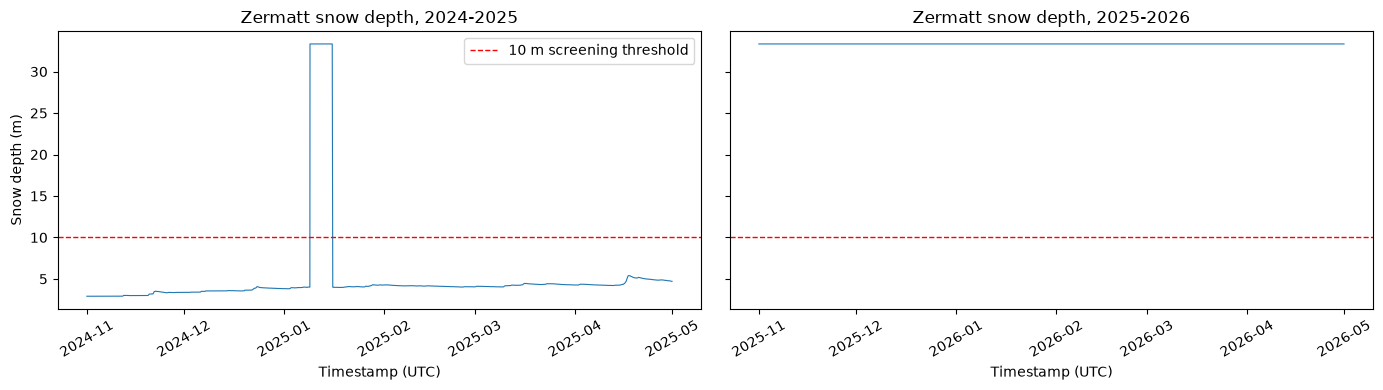

In [42]:
# Snow depth at Zermatt in the affected seasons, with flagged values highlighted
zermatt = structured_hourly_df[structured_hourly_df["destination"] == "Zermatt"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, season in zip(axes, sorted(flagged_snow_depth["season"].unique())):
    season_data = zermatt[zermatt["season"] == season]
    for _, group in season_data.groupby("weather_point_id"):
        group = group.sort_values("timestamp")
        ax.plot(group["timestamp"], group["snow_depth"], linewidth=0.8)
    ax.axhline(10.0, color="red", linestyle="--", linewidth=1, label="10 m screening threshold")
    ax.set_title(f"Zermatt snow depth, {season}")
    ax.set_xlabel("Timestamp (UTC)")
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Snow depth (m)")
axes[0].legend()
plt.tight_layout()
plt.show()

## 10. Conclusions

### Exploratory Data Analysis

The exploratory analysis revealed several important characteristics of the historical ski-weather dataset.

Precipitation and snowfall are highly skewed, with a large proportion of zero-value days and occasional high-intensity events. This suggests that recent cumulative snowfall and snowfall event intensity may be more informative for ski-condition assessment than daily snowfall alone.

Snow depth generally increases throughout the winter, reaching its highest average levels around March before declining slightly in April. Temperature follows the expected seasonal pattern, with conditions becoming progressively warmer towards the end of the ski season.

Destination-level comparisons demonstrate that resorts differ across several weather dimensions. Snowfall, accumulated snow depth and temperature do not necessarily produce the same destination rankings, highlighting the importance of combining multiple variables when evaluating ski conditions.

Correlation analysis showed a strong positive relationship between precipitation and snowfall, alongside weaker relationships between temperature, snow depth and other weather variables. These relationships should be interpreted cautiously because the analysis combines different destinations, elevations, seasons and dates.

Several data-quality limitations were also identified, including anomalous snow-depth measurements for Zermatt. These observations were retained in the dataset and explicitly flagged rather than corrected or removed, preserving the original data while making potential quality issues transparent.

### Data Preparation

The raw weather data was consolidated into a structured hourly dataset containing 456,624 observations across 18 destinations and five winter seasons. Data types, timestamps, missing values and data integrity were validated, including checks against the original JSON files.

The structured dataset was persisted in Parquet format and successfully reloaded and validated. A general rule-based flag (snow depth above 10 m) marks 4,513 observations (about 0.99% of the dataset), all at Zermatt; they are retained in the dataset and also exported separately for further investigation. The dataset is built by `src/ski_planner/build_dataset.py`, which validates the Parquet output against the raw JSON files.

The findings from this exploration and data preparation phase will guide the selection of variables, aggregation strategies and features for the next stages of the project.